In [3]:
from google.cloud import aiplatform
import numpy as np
from PIL import Image

# 🔧 Replace these with your own values
PROJECT_ID = "instant-stone-474015-u2"
REGION = "us-central1"  # or your region (e.g. "europe-west4")
ENDPOINT_ID = "7123281738058432512"  # found in Vertex AI → Endpoints page
IMAGE_PATH = "fmnist-dataset/fmnist-dataset/test/0.jpg"

# === LOAD AND PREPROCESS IMAGE ===
def preprocess_image(image_path):
    # Load image and convert to grayscale
    img = Image.open(image_path).convert("L")   # "L" = 8-bit grayscale
    
    # Resize to 28x28 pixels (same as Fashion-MNIST)
    img = img.resize((28, 28))
    
    # Convert to NumPy array
    img_array = np.array(img).astype("float32")
    
    # Normalize pixel values to range [0, 1]
    img_array /= 255.0
    
    # Optional: verify shape
    assert img_array.shape == (28, 28), f"Unexpected shape: {img_array.shape}"
    
    return img_array

# Preprocess the image
processed_image = preprocess_image(IMAGE_PATH)

# === PREPARE INSTANCE FOR ENDPOINT ===
instances = [processed_image.tolist()]  # List of one instance

# === CALL THE ENDPOINT ===
aiplatform.init(project=PROJECT_ID, location=REGION)
endpoint = aiplatform.Endpoint(endpoint_name=f"projects/{PROJECT_ID}/locations/{REGION}/endpoints/{ENDPOINT_ID}")

response = endpoint.predict(instances=instances)

print("Prediction response:")
print(response)

Prediction response:
Prediction(predictions=[[-11.1557264, -15.3620691, -11.34237, -15.7847872, -8.44964218, -1.83838058, -9.03598785, -0.238804281, -7.67223454, 5.46774292]], deployed_model_id='9173787360976961536', metadata=None, model_version_id='1', model_resource_name='projects/197916045237/locations/us-central1/models/1253226651873968128', explanations=None)


In [ ]:
import tensorflow as tf

# Load the pre-trained TensorFlow model
model_path = "fashion-mnist-workbench/models/fashion_mnist_model"
model = tf.keras.models.load_model(model_path)

# Verify successful load
model.summary()


In [ ]:
!gcloud auth list

In [1]:
from google.cloud import aiplatform
import numpy as np
from PIL import Image

# 🔧 Replace these with your own values
PROJECT_ID = "instant-stone-474015-u2"
REGION = "us-central1"  # or your region (e.g. "europe-west4")
ENDPOINT_ID = "7123281738058432512"  # found in Vertex AI → Endpoints page
IMAGE_PATH = "fmnist-dataset/fmnist-dataset/test/0.jpg"

# Initialize the Vertex AI client
aiplatform.init(project=PROJECT_ID, location=REGION)

# Load the endpoint by ID
endpoint = aiplatform.Endpoint(endpoint_name=f"projects/{PROJECT_ID}/locations/{REGION}/endpoints/{ENDPOINT_ID}")

print(endpoint.resource_name)

projects/197916045237/locations/us-central1/endpoints/7123281738058432512


AI Prompt: The code should be getting the images from a folder called "test" filled with a lot of jpeg image files with the path "fmnist-dataset/fmnist-dataset/test/" with an image with a path"fmnist-dataset/fmnist-dataset/test/0.jpg" for example. With visual presentation of the model's results (e.g., plots, tables).

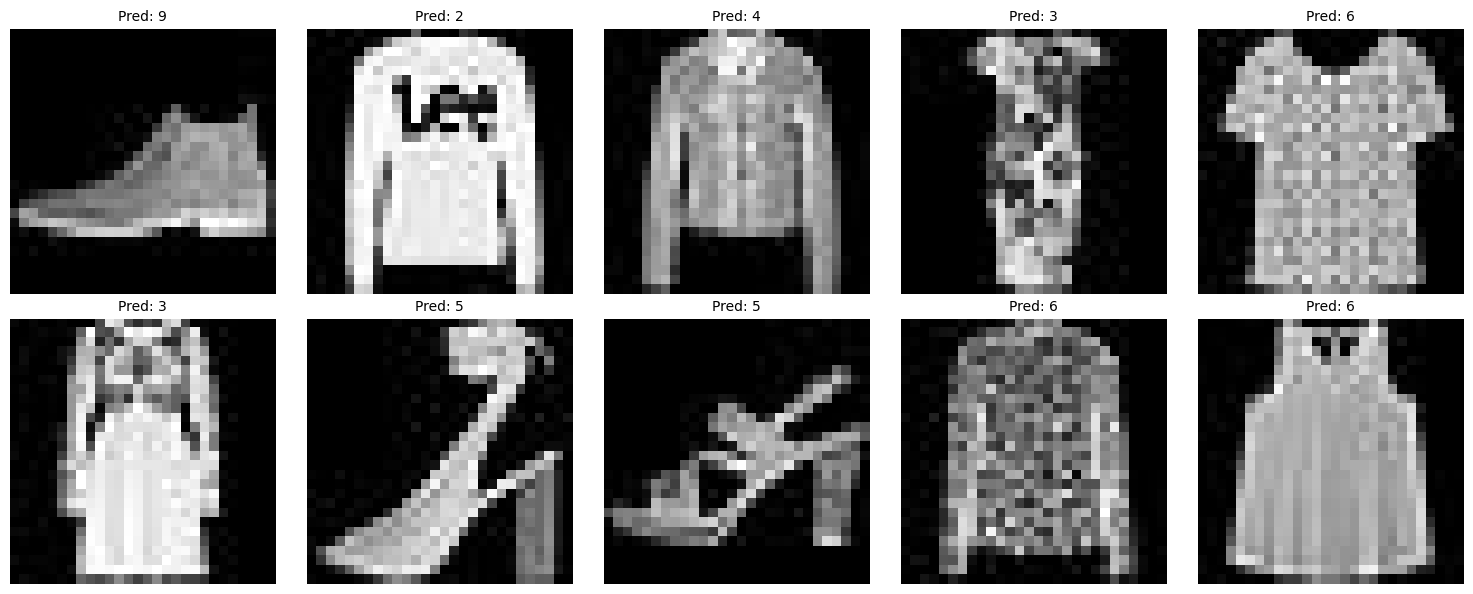

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.cloud import aiplatform

# --- CONFIGURATION ---
PROJECT_ID = "instant-stone-474015-u2"
REGION = "us-central1"
ENDPOINT_ID = "7123281738058432512"
TEST_DIR = "fmnist-dataset/fmnist-dataset/test"

# --- INITIALIZE VERTEX AI ---
aiplatform.init(project=PROJECT_ID, location=REGION)
endpoint = aiplatform.Endpoint(
    endpoint_name=f"projects/{PROJECT_ID}/locations/{REGION}/endpoints/{ENDPOINT_ID}"
)

# --- LOAD AND PREPROCESS IMAGES ---
def preprocess_image(image_path):
    """
    Loads a JPEG image and preprocesses it for Vertex AI endpoint.
    Converts to 28x28 grayscale float32 array with values in [0,1].
    """
    img = Image.open(image_path).convert("L")  # Convert to grayscale
    img = img.resize((28, 28))                 # Resize to 28x28
    img_array = np.array(img).astype(np.float32) / 255.0  # Normalize
    return img_array.tolist()  # Convert to list for JSON serialization

# Load all test images
image_paths = [
    os.path.join(TEST_DIR, fname)
    for fname in sorted(os.listdir(TEST_DIR))
    if fname.endswith(".jpg")
]

# Preprocess a few images (you can use all if desired)
instances = [preprocess_image(p) for p in image_paths[:10]]

# --- SEND TO ENDPOINT FOR PREDICTION ---
response = endpoint.predict(instances=instances)
predictions = np.array(response.predictions)

# --- VISUALIZE RESULTS ---
num_images = len(instances)
rows = int(np.ceil(num_images / 5))
cols = min(num_images, 5)

plt.figure(figsize=(15, 3 * rows))

for i, (image_path, pred) in enumerate(zip(image_paths[:num_images], predictions)):
    plt.subplot(rows, cols, i + 1)
    img = Image.open(image_path).convert("L")
    plt.imshow(img, cmap="gray")
    predicted_class = np.argmax(pred)
    plt.title(f"Pred: {predicted_class}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# --- PATH TO YOUR MODEL DIRECTORY ---
MODEL_PATH = "fashion-mnist-workbench/fashion-mnist2/"  # Folder containing saved_model.pb

# --- LOAD THE MODEL ---
print("Loading model from:", MODEL_PATH)
model = keras.layers.TFSMLayer(MODEL_PATH, call_endpoint="serving_default")
print("✅ Model loaded successfully!")

# --- MODEL SUMMARY ---
model.summary()


Loading model from: fashion-mnist-workbench/fashion-mnist2/


2025-10-14 12:05:07.563974: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


✅ Model loaded successfully!


AttributeError: 'TFSMLayer' object has no attribute 'summary'

Please provide a code snippet that allow for comparison between the deployed model and the pre-trained model loaded with TensorFlow for the measurements performance of both models with the relevant metrics such as accuracy OR F1 score.

3

In [17]:
import os
import re
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from google.cloud import aiplatform
import pandas as pd

# -------------------------
# CONFIGURATION
# -------------------------
PROJECT_ID = "instant-stone-474015-u2"
REGION = "us-central1"
ENDPOINT_ID = "7123281738058432512"
LOCAL_MODEL_PATH = "fashion-mnist-workbench/fashion-mnist2"
TEST_DIR = "fmnist-dataset/fmnist-dataset/test"
TEST_CSV = "fmnist-dataset/fmnist-dataset/test.csv"

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# -------------------------
# LOAD LOCAL MODEL
# -------------------------
local_model = tf.keras.layers.TFSMLayer(LOCAL_MODEL_PATH, call_endpoint="serving_default")
print("✅ Local TensorFlow model loaded!")

# -------------------------
# CONNECT TO VERTEX AI ENDPOINT
# -------------------------
aiplatform.init(project=PROJECT_ID, location=REGION)
endpoint = aiplatform.Endpoint(
    endpoint_name=f"projects/{PROJECT_ID}/locations/{REGION}/endpoints/{ENDPOINT_ID}"
)
print("✅ Connected to Vertex AI endpoint!")

# -------------------------
# IMAGE PREPROCESSING
# -------------------------
def preprocess_image(image_path):
    img = Image.open(image_path).convert("L").resize((28, 28))
    img_array = np.array(img).astype("float32") / 255.0
    return img_array

# -------------------------
# LOAD TEST DATASET
# -------------------------
if os.path.exists(TEST_CSV):
    print(f"📄 Loading labels from {TEST_CSV}")
    df = pd.read_csv(TEST_CSV)
    filenames = df["filename"].astype(str).tolist()
    labels = df["label"].astype(int).tolist()
else:
    print("⚠️ test.csv not found — inferring labels from filenames.")
    filenames, labels = [], []
    for fname in os.listdir(TEST_DIR):
        if fname.lower().endswith((".jpg", ".png", ".jpeg")):
            filenames.append(fname)
            match = re.match(r"(\d+)", fname)
            label = int(match.group(1)) if match else 0
            labels.append(label)

# Load and preprocess images
X_test, y_test_classes = [], []
for fname, label in zip(filenames, labels):
    path = os.path.join(TEST_DIR, fname)
    if os.path.exists(path):
        X_test.append(preprocess_image(path))
        y_test_classes.append(label)

X_test = np.array(X_test)
y_test_classes = np.array(y_test_classes)

print(f"✅ Loaded {len(X_test)} test images.")
print("Example filenames:", filenames[:5])

# -------------------------
# LOCAL MODEL PREDICTION
# -------------------------
print("🔍 Running local model predictions...")
X_test_expanded = np.expand_dims(X_test, axis=-1)

local_output = local_model(X_test_expanded)
if isinstance(local_output, dict):
    local_preds = local_output[list(local_output.keys())[0]].numpy()
else:
    local_preds = local_output.numpy()

print("Local prediction shape:", local_preds.shape)
local_pred_classes = np.argmax(local_preds, axis=1)
print("✅ Local model predictions complete!")

# -------------------------
# VERTEX AI PREDICTION (BATCHED)
# -------------------------
def predict_in_batches(endpoint, X, batch_size=100):
    preds_all = []
    n = len(X)
    print(f"📦 Sending {n} instances in batches of {batch_size}...")
    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)
        batch = X[start:end]
        instances = [x.tolist() for x in batch]
        resp = endpoint.predict(instances=instances)
        preds_all.append(np.array(resp.predictions))
        print(f"✅ Processed batch {start // batch_size + 1}/{(n + batch_size - 1) // batch_size}")
    return np.vstack(preds_all)

vertex_preds = predict_in_batches(endpoint, X_test, batch_size=100)
vertex_pred_classes = np.argmax(vertex_preds, axis=1)
print("✅ Vertex model predictions complete!")

# -------------------------
# EVALUATION
# -------------------------
local_acc = accuracy_score(y_test_classes, local_pred_classes)
vertex_acc = accuracy_score(y_test_classes, vertex_pred_classes)
local_f1 = f1_score(y_test_classes, local_pred_classes, average='weighted')
vertex_f1 = f1_score(y_test_classes, vertex_pred_classes, average='weighted')

print("\n📊 PERFORMANCE COMPARISON")
print(f"Local Model  - Accuracy: {local_acc:.4f}, F1-score: {local_f1:.4f}")
print(f"Vertex Model - Accuracy: {vertex_acc:.4f}, F1-score: {vertex_f1:.4f}")


✅ Local TensorFlow model loaded!
✅ Connected to Vertex AI endpoint!
📄 Loading labels from fmnist-dataset/fmnist-dataset/test.csv
✅ Loaded 10000 test images.
Example filenames: ['0.jpg', '1.jpg', '2.jpg', '3.jpg', '4.jpg']
🔍 Running local model predictions...
Local prediction shape: (10000, 10)
✅ Local model predictions complete!
📦 Sending 10000 instances in batches of 100...
✅ Processed batch 1/100
✅ Processed batch 2/100
✅ Processed batch 3/100
✅ Processed batch 4/100
✅ Processed batch 5/100
✅ Processed batch 6/100
✅ Processed batch 7/100
✅ Processed batch 8/100
✅ Processed batch 9/100
✅ Processed batch 10/100
✅ Processed batch 11/100
✅ Processed batch 12/100
✅ Processed batch 13/100
✅ Processed batch 14/100
✅ Processed batch 15/100
✅ Processed batch 16/100
✅ Processed batch 17/100
✅ Processed batch 18/100
✅ Processed batch 19/100
✅ Processed batch 20/100
✅ Processed batch 21/100
✅ Processed batch 22/100
✅ Processed batch 23/100
✅ Processed batch 24/100
✅ Processed batch 25/100
✅ Proc

Task 3.4: After evaluating the performances of the deployed vertex model (Accuracy: 0.8779, F1-score: 0.8779) and the local model (Accuracy: 0.8803, F1-score: 0.8799) that was loaded with TensorFlow it was seen that the model performances were close however, the local model had a slight edge on the accuracy by 0.0024 and f1 score by 0.0020 over the vertex.  The local supervised model also had a greater ratio of true positives and true negatives in relation to predictions made. The proportion of positive identifications was 
actually correct more than the vertex model (higher precision). The proportion of actual positives identified by the local was identified correctly more than the vertex model (higher recall). This could be because of things like hyperparameters such as the learning rate which effects the objective function where the model may manouver to the optima causing the taining to be more unstable or slow if the values aren't optimal. If there was a difference in methods to avoid overfitting like dropout which is simpler and less computationally expensive, drop connect provides stronger regularisation but is more computationally expensive which will effect the performance. If there were a difference in pooling algorithms used average or max could convolutional neural networks that could affect performance.

Task 4.2: After evaluating the performances of the trained model and the pre trained models (deployed vertex model and the local model that was loaded with TensorFlow) it was seen that the model performances were close however, the trained convolutionary neural network had an accuracy of 0.9162 and an f1-score of 0.9151. Trained model will be compared to the local pre trained one because of the fact that out of the pre trained models the local one had the best performance . The trained model had an edge on the accuracy by 0.0359 and f1 score by 0.0352 over the local pretrained model. The trained supervised model had a greater (than the local pretrained model) ratio of true positives and true negatives in relation to predictions made. The proportion of positive identifications made by the trained model was actually correct more than the local pretrained model (higher precision). The proportion of actual positives identified by the trained model was identified correctly more than the pretrained local model (higher recall). The difference in performances could be due to the transferring the learning that may have been trained on a dataset would be less suited to make predictions than the model that was trained on the specific dataset. However, the performance of the pre trained was still commendable because it may have been trained on similar data. But the fact that it had good performance on a potentially different dataset means that the model has good generalisability. If there were a difference in pooling algorithms used average or max could convolutional neural networks that could affect performance. 

2025-11-04 16:50:10.207680: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-11-04 16:50:13.459540: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/opt/conda/lib/python3.10/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at te

✅ Loaded 60000 training images and 10000 test images.


2025-11-04 16:52:51.055897: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,546 (943.54 KB)

 Trainable params: 241,546 (943.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 36s 37ms/step - accuracy: 0.8030 - loss: 0.5438 - val_accuracy: 0.8669 - val_loss: 0.3593
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.8790 - loss: 0.3299 - val_accuracy: 0.8809 - val_loss: 0.3221
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 37ms/step - accuracy: 0.8983 - loss: 0.2808 - val_accuracy: 0.8991 - val_loss: 0.2719
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.9089 - loss: 0.2496 - val_accuracy: 0.9051 - val_loss: 0.2529
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.9160 - loss: 0.2269 - val_accuracy: 0.9070 - val_loss: 0.2551
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.9236 - loss: 0.2065 - val_accuracy: 0.9091 - val_loss: 0.2408
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 33s 35ms/step - accuracy: 0.9294 - loss: 0.1889 - val_accuracy: 0.9142 - val_loss: 0.2397
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.9344 - loss: 0.1744 - 

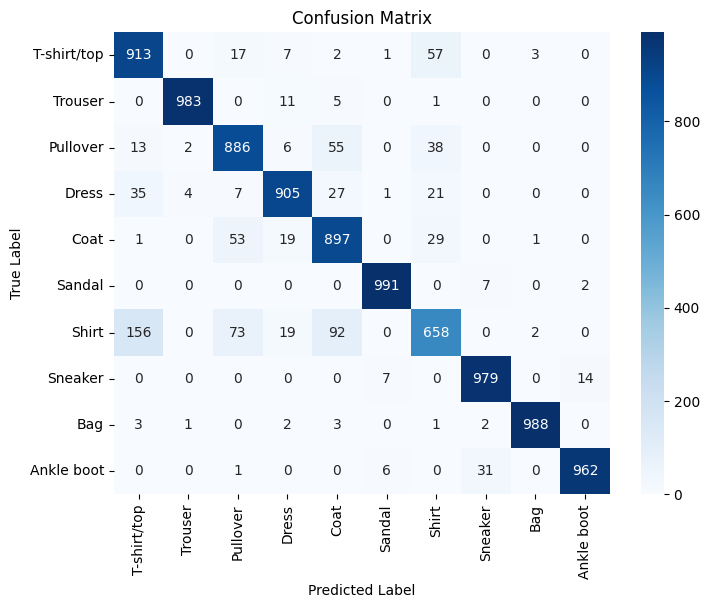

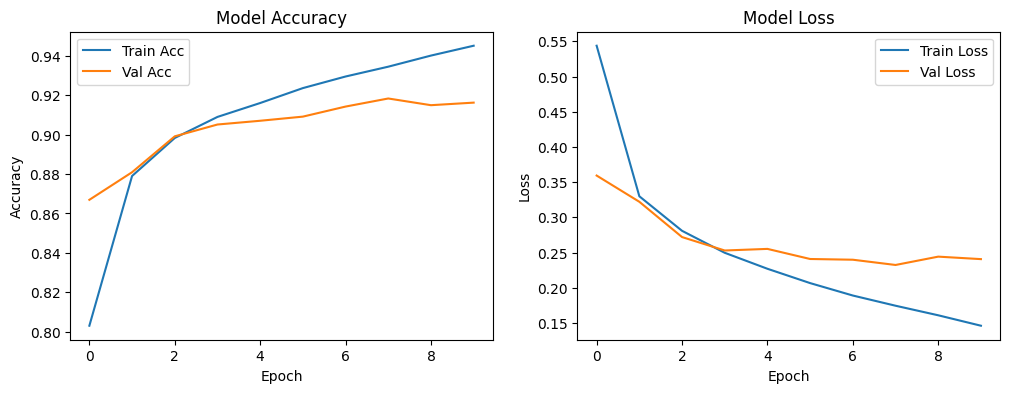

💾 Model saved to 'fashion-mnist-workbench/fashion-mnist-smart.keras'


In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns

# ----------------------------
# CONFIGURATION
# ----------------------------
TRAIN_DIR = "fmnist-dataset/fmnist-dataset/train"
TEST_DIR = "fmnist-dataset/fmnist-dataset/test"
TRAIN_CSV = "fmnist-dataset/fmnist-dataset/train.csv"
TEST_CSV = "fmnist-dataset/fmnist-dataset/test.csv"

IMG_SIZE = (28, 28)
BATCH_SIZE = 64
EPOCHS = 10
NUM_CLASSES = 10

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# ----------------------------
# HELPER FUNCTION
# ----------------------------
def load_images_from_csv(folder, csv_file):
    """Load images and true labels from a CSV file with 'filename' and 'label' columns."""
    df = pd.read_csv(csv_file)
    images, labels = [], []
    for _, row in df.iterrows():
        img_path = os.path.join(folder, str(row['filename']))
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('L').resize(IMG_SIZE)
            img_array = np.array(img, dtype=np.float32) / 255.0
            images.append(img_array)
            labels.append(int(row['label']))
        else:
            print(f"⚠️ Image not found: {img_path}")
    X = np.array(images).reshape(-1, 28, 28, 1)
    y = np.array(labels)
    y_onehot = to_categorical(y, NUM_CLASSES)
    return X, y, y_onehot

# ----------------------------
# LOAD DATASET
# ----------------------------
X_train, y_train_labels, y_train = load_images_from_csv(TRAIN_DIR, TRAIN_CSV)
X_test, y_test_labels, y_test = load_images_from_csv(TEST_DIR, TEST_CSV)

print(f"✅ Loaded {len(X_train)} training images and {len(X_test)} test images.")

# ----------------------------
# MODEL ARCHITECTURE
# ----------------------------
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ----------------------------
# TRAIN MODEL
# ----------------------------
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

# ----------------------------
# EVALUATE MODEL
# ----------------------------
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\n✅ Test Accuracy (Keras): {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# ----------------------------
# DETAILED METRICS (Accuracy & F1)
# ----------------------------
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Overall Accuracy and F1-score
acc = accuracy_score(y_test_labels, y_pred_classes)
f1 = f1_score(y_test_labels, y_pred_classes, average='weighted')

print("\n📊 DETAILED PERFORMANCE METRICS")
print(f"Accuracy (sklearn): {acc:.4f}")
print(f"F1-score (weighted): {f1:.4f}")

# Per-class F1-score and report
print("\nClassification Report:")
print(classification_report(y_test_labels, y_pred_classes, target_names=CLASS_NAMES))

# Confusion Matrix Visualization
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test_labels, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# ----------------------------
# VISUALIZE TRAINING RESULTS
# ----------------------------
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# ----------------------------
# SAVE MODEL
# ----------------------------
os.makedirs("fashion-mnist-workbench", exist_ok=True)
model.save("fashion-mnist-workbench/fashion-mnist-smart.keras")
print("💾 Model saved to 'fashion-mnist-workbench/fashion-mnist-smart.keras'")


In [7]:
import tensorflow as tf

# Load your trained model
model = tf.keras.models.load_model("fashion-mnist-workbench/fashion-mnist-smart.keras")

# Export to TensorFlow SavedModel format for serving/inference
export_path = "fashion-mnist-workbench/fashion-mnist-smart-export/1"
model.export(export_path)  # ✅ use export(), not save()

print(f"✅ Model exported successfully to {export_path}")


Saved artifact at 'fashion-mnist-workbench/fashion-mnist-smart-export/1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  140581731358800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581978527824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581988089376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581731350336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581731351392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581731350688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581731350512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140580813674048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140580813677568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140580813683200: TensorSpec(shape=(), dtype=tf.res

Main AI prompts for programming:
1.please provide a code snippet on google cloud access the endpoint "fashion-mnist-deployment" from python.

2.Please provide a code snippet for preprocessing an image file content for submission to the endpoint. 
 the endpoint expects to receive a list of instances, where each instance will have following characteristics: Type: list, Shape: (28,28), Value type: float32,  Value range: 0.
 
3.Please provide code snippet to load the pre-trained model in the "fashion-mnist-workbench" package using TensorFlow/Keras.
 
4.Please provide test image path in the fmnist-dataset
 
 
5.How to check if Vertex AI was initialized in a different region.
 
6.Please provide a code snippet for preprocessing an image file content for submission to the endpoint. the endpoint expects to receive a list of instances, where each instance will have following characteristics: Type: list, Shape: (28,28), Value type: float32, Value range: 0. The code should be getting the images from a folder called "test" filled with a lot of jpeg image files with the path "fmnist-dataset/fmnist-dataset/test/" with an image with a path"fmnist-dataset/fmnist-dataset/test/0.jpg" for example. With visual presentation of the model's results (e.g., plots, tables).
 
7.Please provide a code snippet that can load a pre trained model fashion-mnist-workbench/fashion-mnist2/saved_model.pb using TensorFlow/Keras.
 
8.Please provide a code snippet that allow for comparison between the deployed model and the pre-trained model loaded with TensorFlow for the measurements performance of both models with the relevant metrics such as accuracy OR F1 score.
 
9.Please provide a code snippet that assists me build and instantiate a new neural network architecture using TensorFlow/Keras with the appropiate hyperparameters because each image depicts a fashion product from one of 10 categories, such as clothing items and accessories maybe 10 neurons in the output layer and other hyperparameters. To be trained and tested on the fashion-mnist dataset. The dataset file will contain two directories: "train" and "test".
 
10.Assist in modifying the existing CNN code so it automatically detects whether there are subfolders and switches between the two loading methods.

11.Use batches to feed the thousands of images.

12.There are csv files named "test.csv" and "train.csv" corresponding to the test and train folders in the paths fmnist-dataset/fmnist-dataset/test.csv or fmnist-dataset/fmnist-dataset/train.csv each of which have a "filename" column with image names like "0,jpg" for example and a "label" column for labels between 0-9 that could solve "the code can’t infer which class each image belongs to" problem

13.Please help me edit the new Fashion-MNIST CNN code so that it uses the test.csv and train csv files described to get the true labels for the images.

14.How to Export model ("fashion-mnist-workbench/fashion-mnist-smart.keras") artifacts for inference and explanation.

https://chatgpt.com/share/690ba7fc-3234-8004-b708-3ef9d47bd61e

[1] OpenAI, ChatGPT (GPT-5), 2025. [Online]. Available: https://chat.openai.com/